# Part 4: Does GARCH-over-ML Generalize Beyond JPM and the S&P 500?

### Ramith Vaid | NTU Singapore

Part 1 found GARCH(1,1) beating a Gradient Boosting model on 21-day volatility forecasts for JPM and the S&P 500 (RMSE 4.17 vs. 4.82 and 3.47 vs. 4.70). Those two series are both US equity risk, and each result came from one 250-day test window. This part asks whether the ranking holds on a wider set of assets and on more than one window.

**First, a correction to the target.** The forward realized-volatility target in `garch_utils.compute_forward_realized_vol` is the volatility over days t+21 to t+41, not over the next 21 days starting tomorrow as its docstring says: it applies `rolling(h).std()` after a `shift(-h)`, which already gives the std of days t+1 to t+h, and then shifts by another h-1 days. Part 1's GARCH-vs-ML RMSEs were scored against that target, so the GARCH forecast of days t+1 to t+21 was compared with the realized volatility of a window that starts 20 days later. Section 2 shows this directly, and section 3 re-runs Part 1's JPM and S&P 500 comparison under the corrected target. Parts 4 to 8 use the corrected target (`compute_forward_realized_vol_aligned`, appended to `garch_utils.py`; the original function is unchanged so Part 1 still reproduces).

**Two other design points.**
- *Information timing.* Every forecast is made at the close of day t from data through day t: GARCH is fit on the 750 returns ending at day t (including it) and its term structure gives the average variance over days t+1 to t+21; the ML features use only data through day t.
- *Embargo.* Part 1 trained the ML model on every row before the test window, but the last 21 of those rows have targets that reach into the test window. Here the model is trained only on rows whose forward window ends before the first scored day.

**Design.** Ten assets across equities, an equity index, international equity, REITs, gold, long Treasuries, FX and crypto. For each, three non-overlapping blocks of 250 scored days (the last 750 days with a complete 21-day forward window), GARCH refit every day on the trailing 750 returns, and one Gradient Boosting model per block (Part 1's settings, trained on all earlier data with the embargo). Each GARCH refit is checked against a constant-variance model, which GARCH nests; a fit that does worse than that is a failed optimization and is replaced by the previous day's parameters (the count is printed). A naive forecast (the trailing 21-day realized volatility, a random walk in volatility) is included as a reference, since a ranking between two models means little if neither beats it. Losses are compared with a Diebold-Mariano test using a Newey-West variance with 20 lags, because consecutive 21-day targets overlap. The data end date is pinned to 2026-10-13.

In [1]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from garch_utils import (
    run_full_pipeline, compute_forward_realized_vol, compute_forward_realized_vol_aligned,
    prepare_vol_data, make_blocks, eval_positions, rolling_garch_term_structure, fit_garch_fast,
    ml_block_forecast, score_forecasts, dm_test, garch_neg_log_likelihood_fast
)
print('Libraries loaded.')

Libraries loaded.


## 1. Data: ten assets, same start and pinned end date as Parts 1 to 3

In [2]:
UNIVERSE = {
    'JPM':      ('JPMorgan Chase', 'US equity'),
    '^GSPC':    ('S&P 500', 'US equity index'),
    'AAPL':     ('Apple', 'US equity'),
    'XOM':      ('Exxon Mobil', 'US equity'),
    'EEM':      ('iShares MSCI Emerging Markets', 'International equity ETF'),
    'VNQ':      ('Vanguard Real Estate', 'REIT ETF'),
    'GLD':      ('SPDR Gold', 'Commodity ETF'),
    'TLT':      ('iShares 20+ Year Treasury', 'Bond ETF'),
    'EURUSD=X': ('EUR/USD', 'FX'),
    'BTC-USD':  ('Bitcoin', 'Crypto'),
}
START, END = '2014-01-01', '2026-10-14'  # END is exclusive: last row is 2026-10-13

close = {}
for tk, (name, cls) in UNIVERSE.items():
    d = yf.download(tk, start=START, end=END, progress=False)
    close[tk] = d['Close'].squeeze().dropna()
    c = close[tk]
    print(f'{name:<32} {tk:<9} {cls:<26} {len(c):>5} prices, {c.index[0].date()} to {c.index[-1].date()}')

JPMorgan Chase                   JPM       US equity                   3214 prices, 2014-01-02 to 2026-10-13
S&P 500                          ^GSPC     US equity index             3214 prices, 2014-01-02 to 2026-10-13


Apple                            AAPL      US equity                   3214 prices, 2014-01-02 to 2026-10-13


Exxon Mobil                      XOM       US equity                   3214 prices, 2014-01-02 to 2026-10-13
iShares MSCI Emerging Markets    EEM       International equity ETF    3214 prices, 2014-01-02 to 2026-10-13


Vanguard Real Estate             VNQ       REIT ETF                    3214 prices, 2014-01-02 to 2026-10-13
SPDR Gold                        GLD       Commodity ETF               3214 prices, 2014-01-02 to 2026-10-13


iShares 20+ Year Treasury        TLT       Bond ETF                    3214 prices, 2014-01-02 to 2026-10-13
EUR/USD                          EURUSD=X  FX                          3327 prices, 2014-01-01 to 2026-10-13


Bitcoin                          BTC-USD   Crypto                      4410 prices, 2014-09-17 to 2026-10-13


## 2. The target alignment, checked on synthetic returns

For a known return series, the original target at day t should equal the annualized std of returns on days t+1 to t+21 if it matches its docstring. It does not: it equals the std of days t+21 to t+41. The aligned version matches the first.

In [3]:
rng = np.random.default_rng(0)
r = pd.Series(rng.normal(0, 0.01, 200))
frame = pd.DataFrame({'log_return': r})
t = 50
ann = np.sqrt(252) * 100
print(f'std of days t+1..t+21   : {r.iloc[t+1:t+22].std() * ann:.6f}')
print(f'std of days t+21..t+41  : {r.iloc[t+21:t+42].std() * ann:.6f}')
print(f'original target at t    : {compute_forward_realized_vol(frame, 21).iloc[t]:.6f}')
print(f'aligned target at t     : {compute_forward_realized_vol_aligned(frame, 21).iloc[t]:.6f}')

std of days t+1..t+21   : 16.340609
std of days t+21..t+41  : 16.888209
original target at t    : 16.888209
aligned target at t     : 16.340609


## 3. Part 1 re-run under the corrected target

Part 1's configuration (one test window of the last 250 rows, one Gradient Boosting model, GARCH(1,1) refit on 750 days), three ways: **(a)** exactly as published, by calling Part 1's `run_full_pipeline`; **(b)** the corrected target and the corrected information timing, with Part 1's train/test split (no embargo); **(c)** as (b) with the embargo. The windows in (b) and (c) are the last 250 days with a complete forward window, so they are not the identical dates as (a).

In [4]:
rows = []
for tk in ['JPM', '^GSPC']:
    name = UNIVERSE[tk][0]
    c_df = pd.DataFrame({'Close': close[tk]})
    pub = run_full_pipeline(c_df, name, test_size=250, compute_var=False)
    rows.append({'ticker': tk, 'version': '(a) as published', 'n_days': len(pub['comparison']),
                 'garch_rmse': pub['garch_rmse'], 'ml_rmse': pub['ml_rmse']})
    processed, ml = prepare_vol_data(close[tk])
    pos = eval_positions(len(processed), 250)
    dates = processed.index[pos]
    g = rolling_garch_term_structure(processed['log_return'], pos, 750, (21,), fitter=fit_garch_fast,
                                     nll=garch_neg_log_likelihood_fast)['h21']
    actual = ml.loc[dates, 'target_vol']
    for label, emb in (('(b) corrected target, no embargo', 0), ('(c) corrected target, with embargo', 22)):
        m, _ = ml_block_forecast(processed, ml, pos, embargo=emb)
        rows.append({'ticker': tk, 'version': label, 'n_days': len(dates),
                     'garch_rmse': score_forecasts(actual, g)['rmse'], 'ml_rmse': score_forecasts(actual, m)['rmse']})
part1_rerun = pd.DataFrame(rows)
part1_rerun['garch_over_ml'] = part1_rerun['garch_rmse'] / part1_rerun['ml_rmse']
pd.set_option('display.float_format', lambda v: f'{v:,.3f}')
pd.set_option('display.width', 200)
print(part1_rerun.to_string(index=False))

ticker                            version  n_days  garch_rmse  ml_rmse  garch_over_ml
   JPM                   (a) as published     209       4.174    4.817          0.866
   JPM   (b) corrected target, no embargo     250       4.082    4.352          0.938
   JPM (c) corrected target, with embargo     250       4.082    4.368          0.934
 ^GSPC                   (a) as published     209       3.465    4.698          0.738
 ^GSPC   (b) corrected target, no embargo     250       3.374    3.867          0.872
 ^GSPC (c) corrected target, with embargo     250       3.374    3.779          0.893


## 4. Three blocks per asset

For each asset: GARCH(1,1) forecasts of the 21-day average volatility, a Gradient Boosting forecast trained with the embargo, and the naive trailing-volatility forecast, over three non-overlapping 250-day blocks. The leakage check is a truncation test: features computed from data cut off at day t must equal the features computed from the full history at day t. This test is run once per asset before any model is fit.

In [5]:
def truncation_check(close_series, n_checks=5, seed=0):
    full, ml_full = prepare_vol_data(close_series)
    rng = np.random.default_rng(seed)
    cols = [c for c in ml_full.columns if c != 'target_vol']
    ok = True
    for pos_ in rng.integers(300, len(full) - 30, n_checks):
        cut = close_series.iloc[: close_series.index.get_loc(full.index[pos_]) + 1]
        _, ml_cut = prepare_vol_data(cut)
        d = full.index[pos_]
        if d in ml_cut.index and d in ml_full.index:
            ok &= bool(np.allclose(ml_cut.loc[d, cols].values.astype(float), ml_full.loc[d, cols].values.astype(float)))
    return ok

print('Features at day t use only data through day t (truncation test):')
print({tk: truncation_check(close[tk]) for tk in UNIVERSE})

Features at day t use only data through day t (truncation test):


{'JPM': True, '^GSPC': True, 'AAPL': True, 'XOM': True, 'EEM': True, 'VNQ': True, 'GLD': True, 'TLT': True, 'EURUSD=X': True, 'BTC-USD': True}


In [6]:
N_BLOCKS, BLOCK_LEN = 3, 250
fc_rows = []
fit_failures = {}
for tk, (name, cls) in UNIVERSE.items():
    processed, ml = prepare_vol_data(close[tk])
    blocks = make_blocks(len(processed), N_BLOCKS, BLOCK_LEN)
    all_pos = np.concatenate(list(blocks.values()))
    gdf = rolling_garch_term_structure(processed['log_return'], all_pos, 750, (21,), fitter=fit_garch_fast,
                                       nll=garch_neg_log_likelihood_fast)
    g = gdf['h21']
    fit_failures[tk] = gdf.attrs['n_fit_failures']
    for label, pos in blocks.items():
        dates = processed.index[pos]
        m, _ = ml_block_forecast(processed, ml, pos, embargo=22)
        fc_rows.append(pd.DataFrame({
            'ticker': tk, 'block': label, 'actual': ml.loc[dates, 'target_vol'].values,
            'garch': g.loc[dates].values, 'ml': m.values, 'naive': processed.loc[dates, 'realized_vol'].values}, index=dates))
    print(f'{tk:<9} done: {len(all_pos)} scored days, {processed.index[all_pos[0]].date()} to {processed.index[all_pos[-1]].date()}')
fc = pd.concat(fc_rows)
fc.index.name = 'date'
print('Failed GARCH fits (worse than a constant-variance model, replaced by the previous day parameters):', fit_failures)

JPM       done: 750 scored days, 2023-09-18 to 2026-09-14


^GSPC     done: 750 scored days, 2023-09-18 to 2026-09-14


AAPL      done: 750 scored days, 2023-09-18 to 2026-09-14


XOM       done: 750 scored days, 2023-09-18 to 2026-09-14


EEM       done: 750 scored days, 2023-09-18 to 2026-09-14


VNQ       done: 750 scored days, 2023-09-18 to 2026-09-14


GLD       done: 750 scored days, 2023-09-18 to 2026-09-14


TLT       done: 750 scored days, 2023-09-18 to 2026-09-14


EURUSD=X  done: 750 scored days, 2023-10-24 to 2026-09-14


BTC-USD   done: 750 scored days, 2024-09-03 to 2026-09-22
Failed GARCH fits (worse than a constant-variance model, replaced by the previous day parameters): {'JPM': 0, '^GSPC': 0, 'AAPL': 0, 'XOM': 0, 'EEM': 0, 'VNQ': 0, 'GLD': 0, 'TLT': 0, 'EURUSD=X': 0, 'BTC-USD': 0}


## 5. RMSE by asset and block

RMSE and MAE are in annualized percentage points, so they are not comparable across assets with very different volatility levels (Bitcoin against Treasuries); the comparison that carries across assets is the ratio of GARCH's RMSE to the ML model's RMSE, and each model's RMSE as a share of the mean target.

In [7]:
rows = []
for (tk, block), g in fc.groupby(['ticker', 'block'], sort=False):
    row = {'ticker': tk, 'block': block, 'mean_target': g['actual'].mean()}
    for m in ('garch', 'ml', 'naive'):
        s = score_forecasts(g['actual'], g[m])
        row[f'{m}_rmse'] = s['rmse']; row[f'{m}_mae'] = s['mae']; row[f'{m}_bias'] = s['bias']
    row['garch_over_ml'] = row['garch_rmse'] / row['ml_rmse']
    row['winner'] = min(('garch', 'ml', 'naive'), key=lambda m: row[f'{m}_rmse'])
    rows.append(row)
by_block = pd.DataFrame(rows)

pooled_rows = []
for tk, g in fc.groupby('ticker', sort=False):
    row = {'ticker': tk, 'asset_class': UNIVERSE[tk][1], 'n_days': len(g), 'mean_target': g['actual'].mean()}
    for m in ('garch', 'ml', 'naive'):
        s = score_forecasts(g['actual'], g[m])
        row[f'{m}_rmse'] = s['rmse']; row[f'{m}_bias'] = s['bias']
        row[f'{m}_rmse_pct_of_mean'] = 100 * s['rmse'] / row['mean_target']
    row['garch_over_ml'] = row['garch_rmse'] / row['ml_rmse']
    la = (g['garch'] - g['actual']) ** 2; lm = (g['ml'] - g['actual']) ** 2; ln_ = (g['naive'] - g['actual']) ** 2
    row['dm_garch_vs_ml'], row['dm_p_garch_vs_ml'] = dm_test(la, lm, 20)
    row['dm_garch_vs_naive'], row['dm_p_garch_vs_naive'] = dm_test(la, ln_, 20)
    row['dm_ml_vs_naive'], row['dm_p_ml_vs_naive'] = dm_test(lm, ln_, 20)
    pooled_rows.append(row)
pooled = pd.DataFrame(pooled_rows)

print(by_block[['ticker', 'block', 'mean_target', 'garch_rmse', 'ml_rmse', 'naive_rmse', 'garch_over_ml', 'winner']].to_string(index=False))

  ticker   block  mean_target  garch_rmse  ml_rmse  naive_rmse  garch_over_ml winner
     JPM block 1       18.688       6.662    7.212       7.088          0.924  garch
     JPM block 2       24.116      12.198   13.337      15.917          0.915  garch
     JPM block 3       22.221       4.082    4.368       4.919          0.934  garch
   ^GSPC block 1       12.145       4.372    4.931       4.949          0.887  garch
   ^GSPC block 2       15.611      11.336   13.388      12.250          0.847  garch
   ^GSPC block 3       12.727       3.374    3.779       4.518          0.893  garch
    AAPL block 1       21.640       6.018    6.570       7.004          0.916  garch
    AAPL block 2       28.269      17.185   14.845      19.304          1.158     ml
    AAPL block 3       23.715       7.509    8.155       9.223          0.921  garch
     XOM block 1       19.858       5.688    5.390       5.233          1.055  naive
     XOM block 2       22.561       8.924    9.659      10.185   

## 6. Pooled over all 750 days, with Diebold-Mariano tests

A negative Diebold-Mariano statistic means the first model has the lower squared error. With overlapping 21-day targets and three blocks of one asset the effective number of independent observations is small, so the p-values are indicative.

In [8]:
show = ['ticker', 'asset_class', 'mean_target', 'garch_rmse', 'ml_rmse', 'naive_rmse', 'garch_over_ml',
        'garch_rmse_pct_of_mean', 'ml_rmse_pct_of_mean', 'naive_rmse_pct_of_mean']
print(pooled[show].to_string(index=False))
print()
print(pooled[['ticker', 'dm_garch_vs_ml', 'dm_p_garch_vs_ml', 'dm_garch_vs_naive', 'dm_p_garch_vs_naive',
              'dm_ml_vs_naive', 'dm_p_ml_vs_naive']].to_string(index=False))
print()
print(pooled[['ticker', 'garch_bias', 'ml_bias', 'naive_bias']].to_string(index=False))

  ticker              asset_class  mean_target  garch_rmse  ml_rmse  naive_rmse  garch_over_ml  garch_rmse_pct_of_mean  ml_rmse_pct_of_mean  naive_rmse_pct_of_mean
     JPM                US equity       21.675       8.363    9.110      10.453          0.918                  38.586               42.030                  48.225
   ^GSPC          US equity index       13.494       7.280    8.521       8.061          0.854                  53.948               63.149                  59.740
    AAPL                US equity       24.541      11.371   10.489      12.997          1.084                  46.335               42.739                  52.959
     XOM                US equity       22.644       6.857    7.039       7.267          0.974                  30.283               31.087                  32.091
     EEM International equity ETF       18.474       7.237    7.671       7.732          0.943                  39.172               41.525                  41.851
     VNQ        

## 7. Does the ranking generalize?

Counts across the 30 asset-blocks (10 assets x 3 blocks) and the 10 pooled assets, and the same split by asset class.

In [9]:
wins = by_block['winner'].value_counts().reindex(['garch', 'ml', 'naive']).fillna(0).astype(int)
print('Best RMSE per asset-block (of', len(by_block), '):', wins.to_dict())
print('GARCH beat ML in', int((by_block['garch_over_ml'] < 1).sum()), 'of', len(by_block), 'asset-blocks;',
      'in', int((pooled['garch_over_ml'] < 1).sum()), 'of', len(pooled), 'assets pooled')
print('GARCH beat naive in', int((pooled['garch_rmse'] < pooled['naive_rmse']).sum()), 'of', len(pooled), 'assets pooled;',
      'ML beat naive in', int((pooled['ml_rmse'] < pooled['naive_rmse']).sum()))
print('Diebold-Mariano p < 0.05, GARCH vs ML:', int((pooled['dm_p_garch_vs_ml'] < 0.05).sum()), 'assets (of', len(pooled), ')')
print()
print(pooled.groupby('asset_class')['garch_over_ml'].agg(['mean', 'min', 'max', 'count']).round(3).to_string())
print()
print('Median garch_over_ml by block:', by_block.groupby('block')['garch_over_ml'].median().round(3).to_dict())

Best RMSE per asset-block (of 30 ): {'garch': 18, 'ml': 8, 'naive': 4}
GARCH beat ML in 20 of 30 asset-blocks; in 8 of 10 assets pooled
GARCH beat naive in 10 of 10 assets pooled; ML beat naive in 7
Diebold-Mariano p < 0.05, GARCH vs ML: 1 assets (of 10 )

                          mean   min   max  count
asset_class                                      
Bond ETF                 0.977 0.977 0.977      1
Commodity ETF            1.006 1.006 1.006      1
Crypto                   0.816 0.816 0.816      1
FX                       0.984 0.984 0.984      1
International equity ETF 0.943 0.943 0.943      1
REIT ETF                 0.733 0.733 0.733      1
US equity                0.992 0.918 1.084      3
US equity index          0.854 0.854 0.854      1

Median garch_over_ml by block: {'block 1': 0.92, 'block 2': 0.893, 'block 3': 1.004}


## 8. Chart

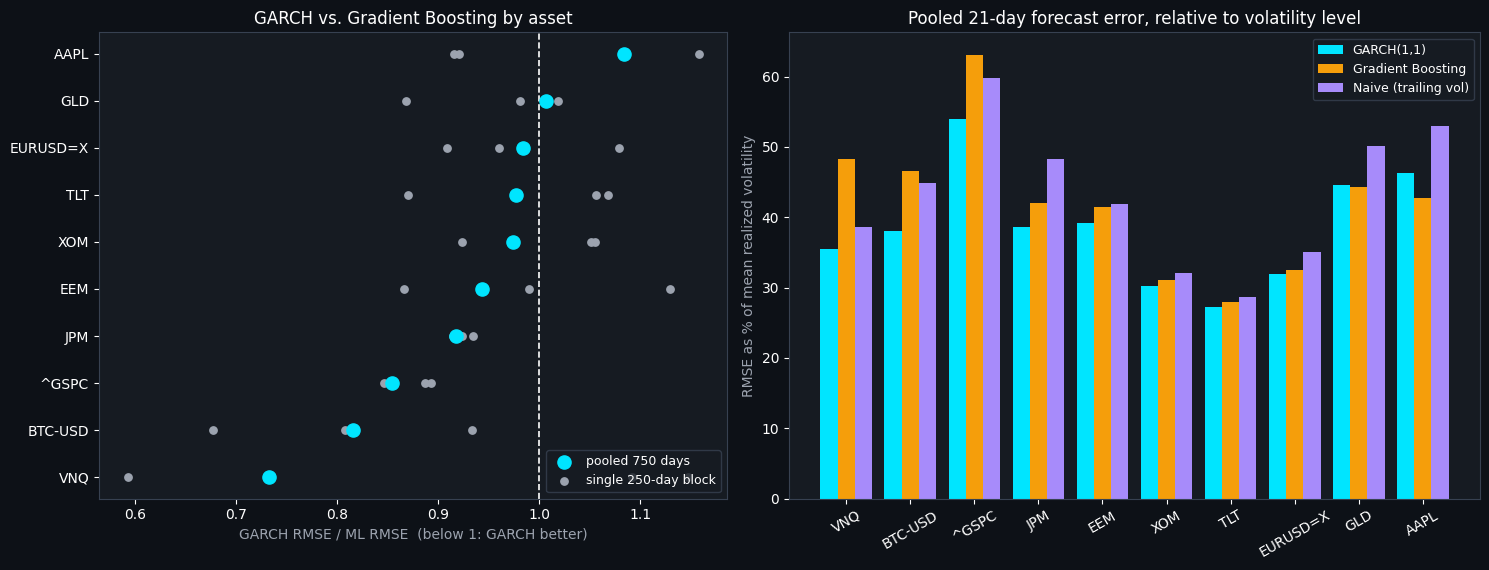

Saved chart_part4_generalization.png


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.8), gridspec_kw={'width_ratios': [1, 1.1]})
fig.patch.set_facecolor('#0d1117')
for ax in axes:
    ax.set_facecolor('#161b22')
    ax.tick_params(colors='white')
    for spine in ax.spines.values():
        spine.set_edgecolor('#374151')
order = list(pooled.sort_values('garch_over_ml')['ticker'])
ax = axes[0]
for i, tk in enumerate(order):
    sub = by_block[by_block.ticker == tk]
    ax.scatter(sub['garch_over_ml'], [i] * len(sub), color='#9ca3af', s=28, zorder=2)
    ax.scatter(pooled.set_index('ticker').loc[tk, 'garch_over_ml'], i, color='#00e5ff', s=90, zorder=3,
               label='pooled 750 days' if i == 0 else None)
ax.scatter([], [], color='#9ca3af', s=28, label='single 250-day block')
ax.axvline(1, color='white', ls='--', lw=1.2)
ax.set_yticks(range(len(order)))
ax.set_yticklabels(order, color='white')
ax.set_xlabel('GARCH RMSE / ML RMSE  (below 1: GARCH better)', color='#9ca3af')
ax.set_title('GARCH vs. Gradient Boosting by asset', color='white', fontsize=12)
ax.legend(facecolor='#161b22', edgecolor='#374151', labelcolor='white', fontsize=9, loc='lower right')
ax = axes[1]
x = np.arange(len(order))
w = 0.27
p = pooled.set_index('ticker').loc[order]
for off, m, col, lab in ((-w, 'garch', '#00e5ff', 'GARCH(1,1)'), (0, 'ml', '#f59e0b', 'Gradient Boosting'), (w, 'naive', '#a78bfa', 'Naive (trailing vol)')):
    ax.bar(x + off, p[f'{m}_rmse_pct_of_mean'], w, color=col, label=lab)
ax.set_xticks(x)
ax.set_xticklabels(order, color='white', rotation=30)
ax.set_ylabel('RMSE as % of mean realized volatility', color='#9ca3af')
ax.set_title('Pooled 21-day forecast error, relative to volatility level', color='white', fontsize=12)
ax.legend(facecolor='#161b22', edgecolor='#374151', labelcolor='white', fontsize=9)
plt.tight_layout()
plt.savefig('chart_part4_generalization.png', dpi=150, bbox_inches='tight', facecolor='#0d1117')
plt.show()
print('Saved chart_part4_generalization.png')

## 9. Summary and saved tables

In [11]:
part1_rerun.to_csv('part4_part1_rerun.csv', index=False)
by_block.to_csv('part4_by_block.csv', index=False)
pooled.to_csv('part4_pooled.csv', index=False)
fc.to_csv('part4_forecasts.csv')
print('=' * 70)
print('PART 4 SUMMARY: DOES GARCH-OVER-ML GENERALIZE?')
print('=' * 70)
print(part1_rerun[['ticker', 'version', 'garch_rmse', 'ml_rmse', 'garch_over_ml']].to_string(index=False))
print()
print(pooled[['ticker', 'asset_class', 'garch_rmse', 'ml_rmse', 'naive_rmse', 'garch_over_ml']].to_string(index=False))
print()
print('Files saved: chart_part4_generalization.png, part4_part1_rerun.csv, part4_by_block.csv, part4_pooled.csv, part4_forecasts.csv')

PART 4 SUMMARY: DOES GARCH-OVER-ML GENERALIZE?
ticker                            version  garch_rmse  ml_rmse  garch_over_ml
   JPM                   (a) as published       4.174    4.817          0.866
   JPM   (b) corrected target, no embargo       4.082    4.352          0.938
   JPM (c) corrected target, with embargo       4.082    4.368          0.934
 ^GSPC                   (a) as published       3.465    4.698          0.738
 ^GSPC   (b) corrected target, no embargo       3.374    3.867          0.872
 ^GSPC (c) corrected target, with embargo       3.374    3.779          0.893

  ticker              asset_class  garch_rmse  ml_rmse  naive_rmse  garch_over_ml
     JPM                US equity       8.363    9.110      10.453          0.918
   ^GSPC          US equity index       7.280    8.521       8.061          0.854
    AAPL                US equity      11.371   10.489      12.997          1.084
     XOM                US equity       6.857    7.039       7.267          0.